In [1]:
import pandas as pd
import numpy as np 

In [2]:
df=pd.read_csv(r"C:\Users\DELL\Desktop\CloudSCOUT\data\cloud_billing.csv")

In [3]:
df.shape

(30, 8)

In [4]:
df.head()

,date,provider,service,region,resource_id,usage_quantity,cost,currency
0,2026-10-01,AWS,Compute,ap-south-1,aws-vm-001,120,4500,INR
1,2026-10-01,AWS,Storage,ap-south-1,aws-storage-001,500,1200,INR
2,2026-10-01,Azure,Compute,centralindia,azure-vm-001,100,3800,INR
3,2026-10-01,Azure,Database,centralindia,azure-db-001,40,2200,INR
4,2026-10-01,GCP,Compute,asia-south1,gcp-vm-001,90,3200,INR


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   date            30 non-null     str  
 1   provider        30 non-null     str  
 2   service         30 non-null     str  
 3   region          30 non-null     str  
 4   resource_id     30 non-null     str  
 5   usage_quantity  30 non-null     int64
 6   cost            30 non-null     int64
 7   currency        30 non-null     str  
dtypes: int64(2), str(6)
memory usage: 3.4 KB


In [6]:
df.isnull().sum()

date              0
provider          0
service           0
region            0
resource_id       0
usage_quantity    0
cost              0
currency          0
dtype: int64

In [7]:
print(df.duplicated().sum())

0


In [8]:
df.describe()

,usage_quantity,cost
count,30.000000,30.000000
mean,208.533333,2830.333333
std,172.520210,1474.249039
min,40.000000,900.000000
25%,98.500000,1242.500000
50%,117.500000,2850.000000
75%,358.750000,4075.000000
max,525.000000,5300.000000


In [9]:
df["provider"].value_counts()

provider
AWS      10
Azure    10
GCP      10
Name: count, dtype: int64

In [10]:
df["service"].value_counts()

service
Compute     15
Storage     10
Database     5
Name: count, dtype: int64

In [11]:
df.groupby("provider")["cost"].sum().sort_values(ascending=False)

provider
Azure    32350
AWS      30390
GCP      22170
Name: cost, dtype: int64

In [12]:
df.groupby("provider")["cost"].mean()

provider
AWS      3039.0
Azure    3235.0
GCP      2217.0
Name: cost, dtype: float64

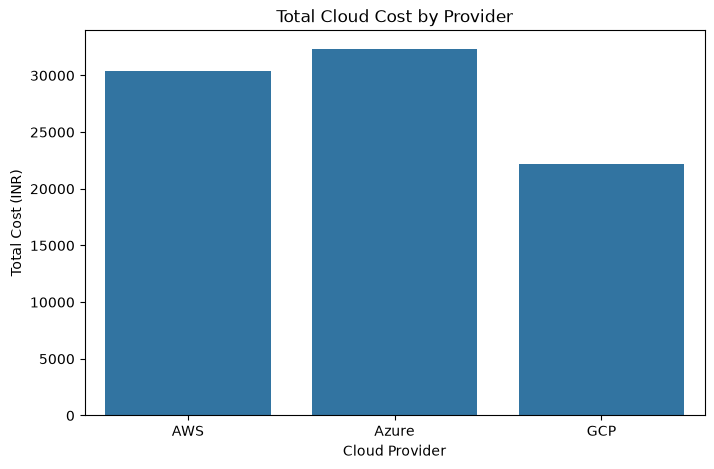

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="provider", y="cost", estimator="sum", errorbar=None)

plt.title("Total Cloud Cost by Provider")
plt.xlabel("Cloud Provider")
plt.ylabel("Total Cost (INR)")

plt.show()

In [14]:
daily_cost = df.groupby("date")["cost"].sum()

daily_cost

date
2026-10-01    15800
2026-10-02    16550
2026-10-03    17230
2026-10-04    17100
2026-10-05    18230
Name: cost, dtype: int64

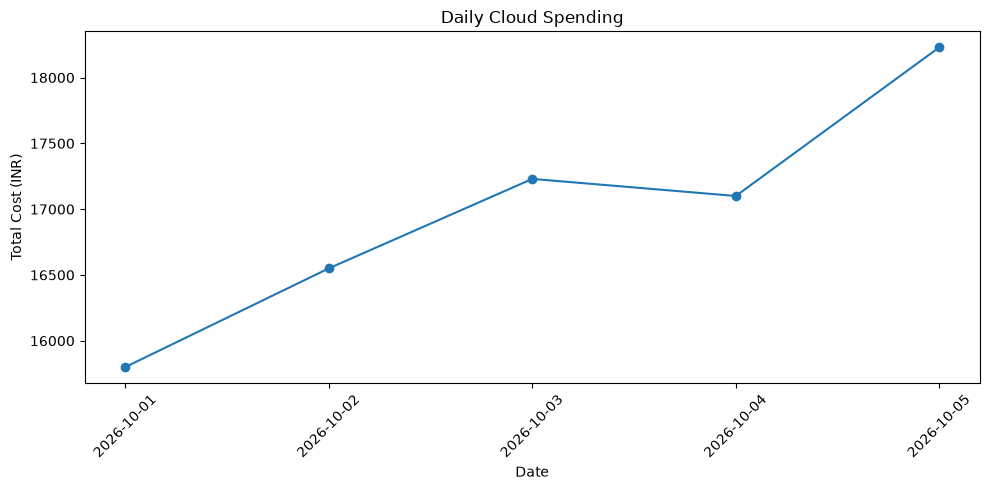

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(daily_cost.index, daily_cost.values, marker="o")

plt.title("Daily Cloud Spending")
plt.xlabel("Date")
plt.ylabel("Total Cost (INR)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

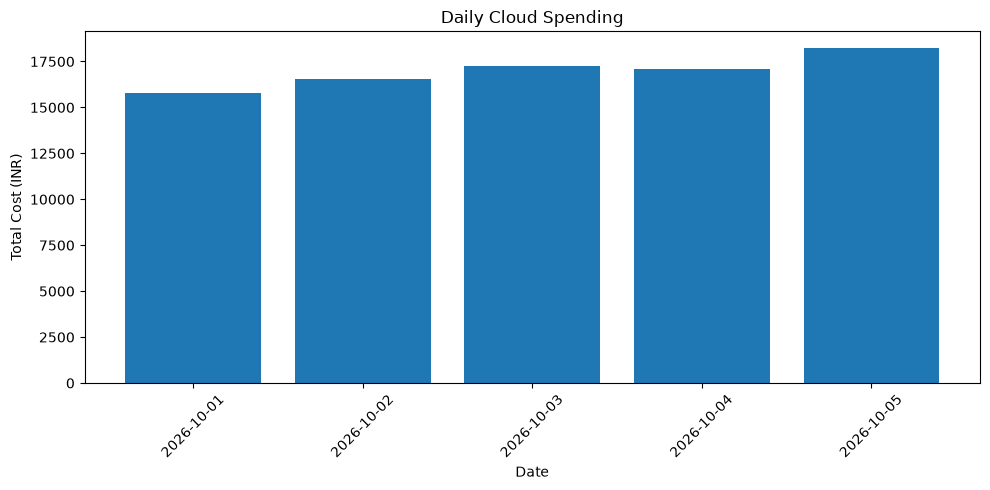

In [16]:
plt.figure(figsize=(10, 5))

plt.bar(daily_cost.index, daily_cost.values)

plt.title("Daily Cloud Spending")
plt.xlabel("Date")
plt.ylabel("Total Cost (INR)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
service_cost = df.groupby("service")["cost"].sum().sort_values(ascending=False)

service_cost

service
Compute     62200
Database    11850
Storage     10860
Name: cost, dtype: int64

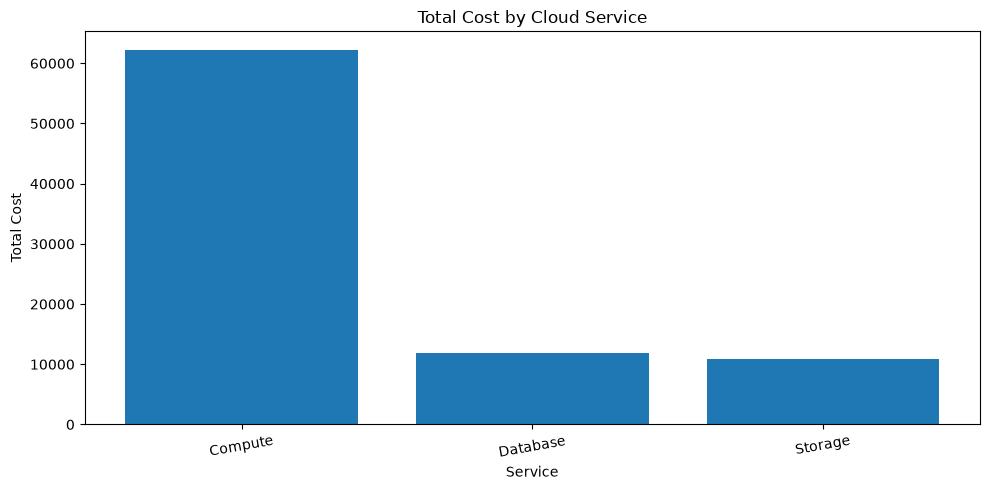

In [18]:
plt.figure(figsize=(10, 5))
plt.bar(service_cost.index, service_cost.values)

plt.title("Total Cost by Cloud Service")
plt.xlabel("Service")
plt.ylabel("Total Cost")
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

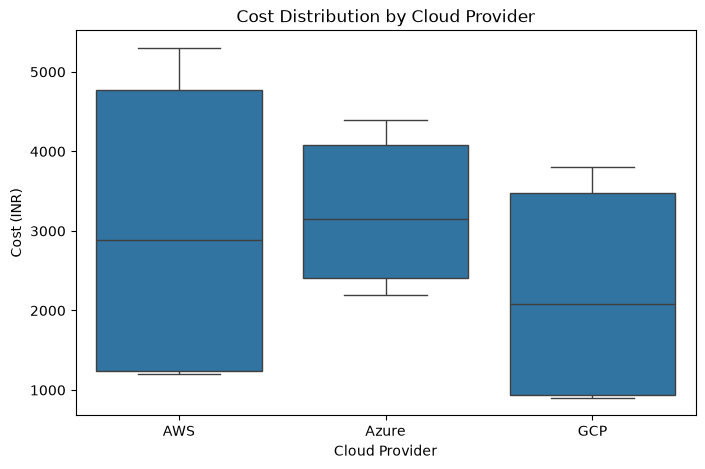

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="provider", y="cost")

plt.title("Cost Distribution by Cloud Provider")
plt.xlabel("Cloud Provider")
plt.ylabel("Cost (INR)")

plt.show()

In [20]:
Q1 = df["cost"].quantile(0.25)
Q3 = df["cost"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -3006.25
Upper bound: 8323.75


In [21]:
df.groupby(["provider", "service"])["cost"].sum().sort_values(ascending=False)

provider  service 
AWS       Compute     24200
Azure     Compute     20500
GCP       Compute     17500
Azure     Database    11850
AWS       Storage      6190
GCP       Storage      4670
Name: cost, dtype: int64

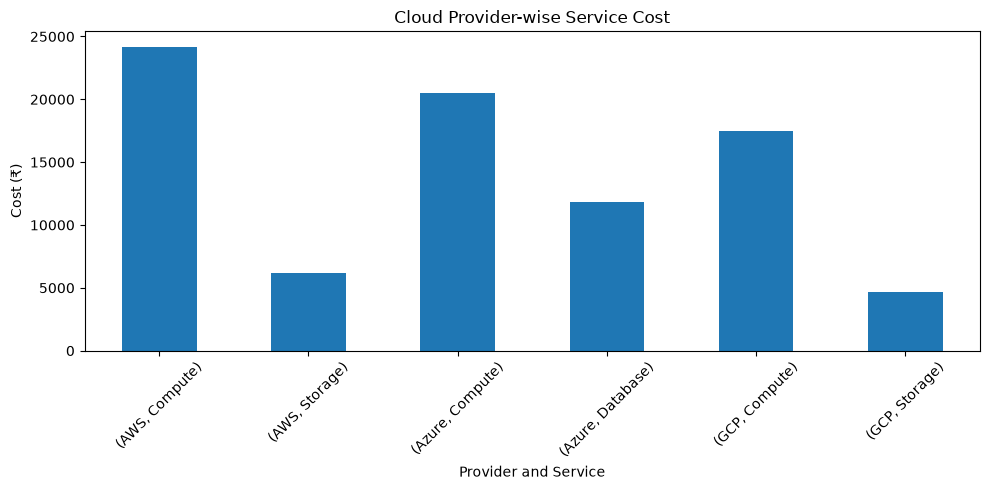

In [22]:
service_cost = df.groupby(['provider', 'service'])['cost'].sum()

service_cost.plot(kind='bar', figsize=(10, 5))

plt.title('Cloud Provider-wise Service Cost')
plt.xlabel('Provider and Service')
plt.ylabel('Cost (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

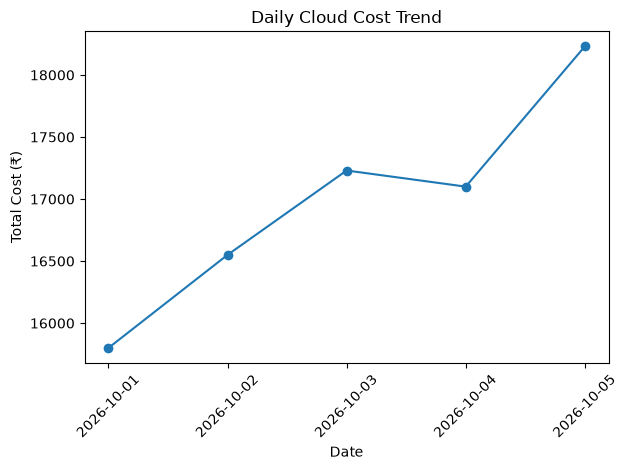

In [23]:
daily_cost = df.groupby('date')['cost'].sum()

plt.plot(daily_cost.index, daily_cost.values,
         marker='o')
plt.title('Daily Cloud Cost Trend')
plt.xlabel('Date')
plt.ylabel('Total Cost (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

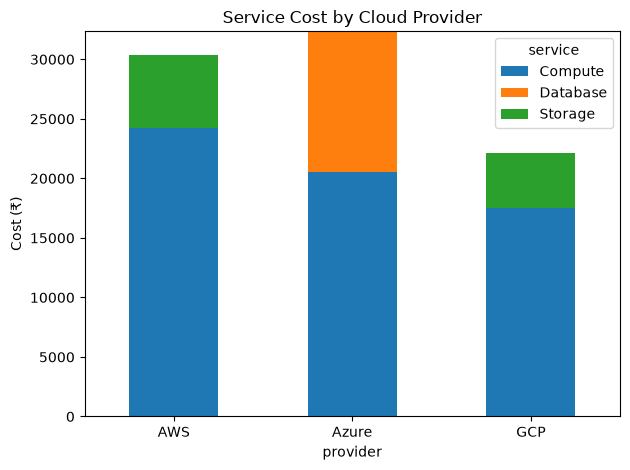

In [24]:
cost_pivot = df.pivot_table(
    index='provider',
    columns='service',
    values='cost',
    aggfunc='sum',
    fill_value=0
)

cost_pivot.plot(kind='bar', stacked=True)
plt.title('Service Cost by Cloud Provider')
plt.ylabel('Cost (₹)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
Q1 = daily_cost.quantile(0.25)
Q3 = daily_cost.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = daily_cost[
    (daily_cost < lower) |
    (daily_cost > upper)
]

print(outliers)

Series([], Name: cost, dtype: int64)
